# Volume 2, Appendix J: Tensors and the Cost of Multiplying Matrices (Python companion)

Exercises first, solutions at the end. We test the Kronecker rules and the vec trick, solve Sylvester equations, implement Strassen's algorithm and count its operations, search for tensor decompositions numerically (and watch the search fail where theory says it must), see the W tensor's degenerate approximations, and measure entanglement. We use `numpy`, `scipy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt
rng = np.random.default_rng(10)

## Exercises

**P10.1 (★) Kronecker rules.** Check the mixed product rule, the eigenvalues, determinant and rank rules of Proposition 10.2 and the vec trick of Proposition 10.4 on random matrices. Then solve a Sylvester equation $AX-XB=C$ through the Kronecker system and with `scipy.linalg.solve_sylvester`, and watch the system become singular when $A$ and $B$ share an eigenvalue (Theorem 10.5).

**P10.2 (★★) Strassen at work.** Implement Strassen's algorithm (Theorem 10.12) recursively, with a cutoff below which `numpy` multiplies directly. Check the result against `A @ B` for random $512\times512$ matrices, and count the scalar multiplications for $n=2^s$ with full recursion: compare with $7^s$ and $8^s$, and check the formula $7n^{\log_27}-6n^2$ for all operations (Exercise 10.6).

**P10.3 (★★) Searching for decompositions.** Write an alternating least squares (ALS) routine that fits a sum of $r$ rank-one tensors to a given tensor. Run it on $\langle2,2,2\rangle$ (Definition 10.10) with $r=6$ and $r=7$, from several random starts. What do the residuals say? Check that the exact Strassen decomposition reproduces the tensor.

**P10.4 (★★) Rank depends on the field, and on limits.** Run ALS on the rotation tensor of Example 10.8 with $r=2$ over $\R$, then with $r=3$, and check the explicit decomposition of the text. Run it on the W tensor (Example 10.9) with $r=2$: plot the residual and the norms of the factors along the iterations.

**P10.5 (★) Entanglement.** Compute the Schmidt coefficients (Theorem 10.14) and the entanglement entropy of the Bell state, of the state of Exercise 10.10, and of many random states in $\C^{8}\otimes\C^{8}$. Compare the average entropy of random states with the maximum $\log_28=3$.

**P10.6 (★) Grids.** Check the eigenvalues of the grid graph $P_m\mathbin\square P_n$ (Example 10.3) and of the discrete Laplacian (Exercise 10.11), and plot the condition number of the Laplacian on the $n\times n$ grid against $4n^2/\pi^2$.

## Solutions

### P10.1
**How to find it.** `np.kron` is the Kronecker product; `vec` stacks columns, which is `X.flatten(order="F")` in `numpy`. Note that `scipy.linalg.solve_sylvester(A, B, Q)` solves $AX+XB=Q$, so we pass $-B$.

In [2]:
A, B = rng.standard_normal((3, 3)), rng.standard_normal((4, 4))
Cm, D = rng.standard_normal((3, 3)), rng.standard_normal((4, 4))
print("mixed product rule:", np.allclose(np.kron(A, B) @ np.kron(Cm, D), np.kron(A @ Cm, B @ D)))
lam, mu = np.linalg.eigvals(A), np.linalg.eigvals(B)
ev = np.linalg.eigvals(np.kron(A, B))
print("eigenvalues are the products:", np.allclose(np.sort_complex(ev), np.sort_complex(np.outer(lam, mu).ravel())))
print("det rule:", np.isclose(np.linalg.det(np.kron(A, B)), np.linalg.det(A) ** 4 * np.linalg.det(B) ** 3))
L = rng.standard_normal((5, 2)) @ rng.standard_normal((2, 5)); M = rng.standard_normal((3, 3)) @ np.diag([1, 1, 0]) @ rng.standard_normal((3, 3))
print("rank rule:", np.linalg.matrix_rank(np.kron(L, M)), "=", np.linalg.matrix_rank(L), "x", np.linalg.matrix_rank(M))

vec = lambda X: X.flatten(order="F")
P, X, Q = rng.standard_normal((3, 5)), rng.standard_normal((5, 4)), rng.standard_normal((4, 2))
print("vec trick:", np.allclose(vec(P @ X @ Q), np.kron(Q.T, P) @ vec(X)))

m, n = 4, 3
A, B, Cr = rng.standard_normal((m, m)), rng.standard_normal((n, n)), rng.standard_normal((m, n))
K = np.kron(np.eye(n), A) - np.kron(B.T, np.eye(m))
X1 = np.linalg.solve(K, vec(Cr)).reshape((m, n), order="F")
X2 = scipy.linalg.solve_sylvester(A, -B, Cr)
print("Sylvester: Kronecker and scipy agree:", np.allclose(X1, X2), " residual", np.abs(A @ X1 - X1 @ B - Cr).max())
for eps in [1e-1, 1e-4, 1e-8, 0]:
    lamA = np.linalg.eigvals(A)[0]
    Bs = B.astype(complex) + (lamA + eps - np.linalg.eigvals(B)[0]) * np.eye(n)   # shift B to share (almost) an eigenvalue
    Ks = np.kron(np.eye(n), A) - np.kron(Bs.T, np.eye(m))
    print(f"gap {eps:g}: smallest |lambda_i - mu_k| = {np.abs(np.subtract.outer(np.linalg.eigvals(A), np.linalg.eigvals(Bs))).min():.1e},"
          f" condition number of the system {np.linalg.cond(Ks):.1e}")

mixed product rule: True
eigenvalues are the products: True
det rule: True
rank rule: 4 = 2 x 2
vec trick: True
Sylvester: Kronecker and scipy agree: True  residual 6.106226635438361e-16
gap 0.1: smallest |lambda_i - mu_k| = 1.0e-01, condition number of the system 1.0e+02
gap 0.0001: smallest |lambda_i - mu_k| = 1.0e-04, condition number of the system 1.0e+05
gap 1e-08: smallest |lambda_i - mu_k| = 1.0e-08, condition number of the system 1.0e+09
gap 0: smallest |lambda_i - mu_k| = 9.0e-16, condition number of the system 5.6e+15


As the gap closes, the Kronecker system becomes singular: its smallest eigenvalue is $\min|\lambda_i-\mu_k|$.

### P10.2
**How to find it.** Split each matrix into four blocks, form the seven products recursively, assemble. For counting, a separate function returns (multiplications, additions) for full recursion.

In [3]:
def strassen(A, B, cutoff=64):
    n = A.shape[0]
    if n <= cutoff:
        return A @ B
    h = n // 2
    a11, a12, a21, a22 = A[:h, :h], A[:h, h:], A[h:, :h], A[h:, h:]
    b11, b12, b21, b22 = B[:h, :h], B[:h, h:], B[h:, :h], B[h:, h:]
    M1 = strassen(a11 + a22, b11 + b22, cutoff)
    M2 = strassen(a21 + a22, b11, cutoff)
    M3 = strassen(a11, b12 - b22, cutoff)
    M4 = strassen(a22, b21 - b11, cutoff)
    M5 = strassen(a11 + a12, b22, cutoff)
    M6 = strassen(a21 - a11, b11 + b12, cutoff)
    M7 = strassen(a12 - a22, b21 + b22, cutoff)
    return np.block([[M1 + M4 - M5 + M7, M3 + M5], [M2 + M4, M1 - M2 + M3 + M6]])

n = 512
A, B = rng.standard_normal((n, n)), rng.standard_normal((n, n))
t0 = time.perf_counter(); S = strassen(A, B); t1 = time.perf_counter(); P = A @ B; t2 = time.perf_counter()
print(f"n = {n}: max |Strassen - numpy| = {np.abs(S - P).max():.1e}  (entries of size ~{np.abs(P).mean():.0f})")
print(f"time: Strassen with cutoff 64 {1e3*(t1-t0):.0f} ms, numpy's BLAS {1e3*(t2-t1):.0f} ms")

def count(n):          # (multiplications, additions) with full recursion
    if n == 1: return 1, 0
    m, a = count(n // 2)
    return 7 * m, 7 * a + 18 * (n // 2) ** 2
print("  n     mult      7^s       8^s     total ops   7n^log7 - 6n^2   schoolbook 2n^3 - n^2")
for s in range(1, 12):
    n = 2 ** s; m, a = count(n)
    print(f"{n:5d} {m:9d} {7**s:9d} {8**s:10d} {m + a:13d} {round(7 * n ** math.log2(7) - 6 * n * n):15d} {2 * n**3 - n * n:15d}")

n = 512: max |Strassen - numpy| = 4.8e-13  (entries of size ~18)
time: Strassen with cutoff 64 21 ms, numpy's BLAS 3 ms
  n     mult      7^s       8^s     total ops   7n^log7 - 6n^2   schoolbook 2n^3 - n^2
    2         7         7          8            25              25              12
    4        49        49         64           247             247             112
    8       343       343        512          2017            2017             960
   16      2401      2401       4096         15271           15271            7936
   32     16807     16807      32768        111505          111505           64512
   64    117649    117649     262144        798967          798967          520192
  128    823543    823543    2097152       5666497         5666497         4177920
  256   5764801   5764801   16777216      39960391        39960391        33488896
  512  40353607  40353607  134217728     280902385       280902385       268173312
 1024 282475249 282475249 1073741824    197103

The multiplications are exactly $7^s$; the total matches $7n^{\log_27}-6n^2$, and full recursion overtakes the schoolbook count at $n=1024$, as in Exercise 10.6. In wall-clock time, a pure Python recursion cannot beat a tuned BLAS library, whose cache-aware schoolbook kernels run near the peak speed of the processor; Strassen pays off in carefully engineered code for large matrices. Its errors are slightly larger than the schoolbook's, but still of the order of the rounding unit times the size of the entries.

### P10.3
**How to find it.** ALS fixes two factor matrices and solves a linear least squares problem for the third, in turn. With the flattening $T_{(1)}$ and the Khatri–Rao product $B\odot C$ (columns $b_r\otimes c_r$), the update is $A=T_{(1)}(B\odot C)\bigl((B^{\mathsf T}B)*(C^{\mathsf T}C)\bigr)^{-1}$, where $*$ is the entrywise product. A tiny ridge term keeps the inverse finite.

In [4]:
def mm_tensor(n):
    T = np.zeros((n * n, n * n, n * n))
    for i in range(n):
        for j in range(n):
            for k in range(n):
                T[i * n + j, j * n + k, k * n + i] = 1
    return T

def khatri_rao(B, C):
    return np.einsum("jr,kr->jkr", B, C).reshape(-1, B.shape[1])

def cp(A, B, C):
    return np.einsum("ir,jr,kr->ijk", A, B, C)

def als(T, r, iters=2000, ridge=1e-9, seed=0, history=False):
    g = np.random.default_rng(seed)
    I, J, K = T.shape
    A, B, C = (g.standard_normal((d, r)) for d in (I, J, K))
    T1, T2, T3 = T.reshape(I, -1), np.moveaxis(T, 1, 0).reshape(J, -1), np.moveaxis(T, 2, 0).reshape(K, -1)
    hist = []
    for it in range(iters):
        A = T1 @ khatri_rao(B, C) @ np.linalg.inv((B.T @ B) * (C.T @ C) + ridge * np.eye(r))
        B = T2 @ khatri_rao(A, C) @ np.linalg.inv((A.T @ A) * (C.T @ C) + ridge * np.eye(r))
        C = T3 @ khatri_rao(A, B) @ np.linalg.inv((A.T @ A) * (B.T @ B) + ridge * np.eye(r))
        if history and it % 10 == 0:
            hist.append((it, np.linalg.norm(T - cp(A, B, C)), max(np.linalg.norm(A, axis=0) * np.linalg.norm(B, axis=0) * np.linalg.norm(C, axis=0))))
    return np.linalg.norm(T - cp(A, B, C)), (A, B, C), hist

T = mm_tensor(2)
for r in (6, 7):
    res = sorted(als(T, r, seed=s)[0] for s in range(8))
    print(f"r = {r}: residuals from 8 random starts:", " ".join(f"{x:.1e}" for x in res))

# Strassen's decomposition as 7 rank-one tensors (index of a_ij is 2i+j, 0-based; third factor is the transposed output)
e = lambda *pairs: sum(c * np.eye(4)[2 * i + j] for (i, j, c) in pairs)
U = [e((0,0,1),(1,1,1)), e((1,0,1),(1,1,1)), e((0,0,1)), e((1,1,1)), e((0,0,1),(0,1,1)), e((1,0,1),(0,0,-1)), e((0,1,1),(1,1,-1))]
V = [e((0,0,1),(1,1,1)), e((0,0,1)), e((0,1,1),(1,1,-1)), e((1,0,1),(0,0,-1)), e((1,1,1)), e((0,0,1),(0,1,1)), e((1,0,1),(1,1,1))]
Wout = {0: [(0,0,1),(1,1,1)], 1: [(1,0,1),(1,1,-1)], 2: [(0,1,1),(1,1,1)], 3: [(1,0,1),(0,0,1)],
        4: [(0,0,-1),(0,1,1)], 5: [(1,1,1)], 6: [(0,0,1)]}
# M_s contributes to entry (i,k) of AB, i.e. to the coordinate c_{ki} of the third factor
W = [sum(c * np.eye(4)[2 * k + i] for (i, k, c) in Wout[s]) for s in range(7)]
S7 = sum(np.einsum("i,j,k->ijk", U[s], V[s], W[s]) for s in range(7))
print("Strassen's seven rank-one tensors sum to <2,2,2>:", np.array_equal(S7, T))

r = 6: residuals from 8 random starts: 1.0e+00 1.0e+00 1.0e+00 1.0e+00 1.0e+00 1.0e+00 1.0e+00 1.0e+00


r = 7: residuals from 8 random starts: 1.9e-08 4.5e-08 6.5e-08 3.0e-03 1.0e-02 2.1e-02 2.4e-02 2.4e-02
Strassen's seven rank-one tensors sum to <2,2,2>: True


With $r=7$ ALS reaches residuals near zero from most starts: decompositions of length $7$ exist and form a continuous family (the tensor has a large symmetry group, which moves Strassen's decomposition around). With $r=6$ every start stalls at a residual of about $1$: Winograd's theorem says $R(\langle2,2,2\rangle)=7$, and in fact the border rank is $7$ too (Landsberg, 2006), so no rank-$6$ tensor comes close. The numerical evidence agrees with the theorems, but it proves nothing: a stalled search is not a proof of non-existence.

### P10.4
**How to find it.** Reuse `als`. For the W tensor, record the residual and the largest norm of a rank-one term every ten iterations.

rotation tensor, real ALS with r = 2: 1.0e+00 1.0e+00 1.0e+00 1.0e+00 1.0e+00


rotation tensor, real ALS with r = 3: 3.0e-08 1.7e-07 5.9e-09 4.7e-09 8.7e-09
explicit decomposition of the text is exact: True


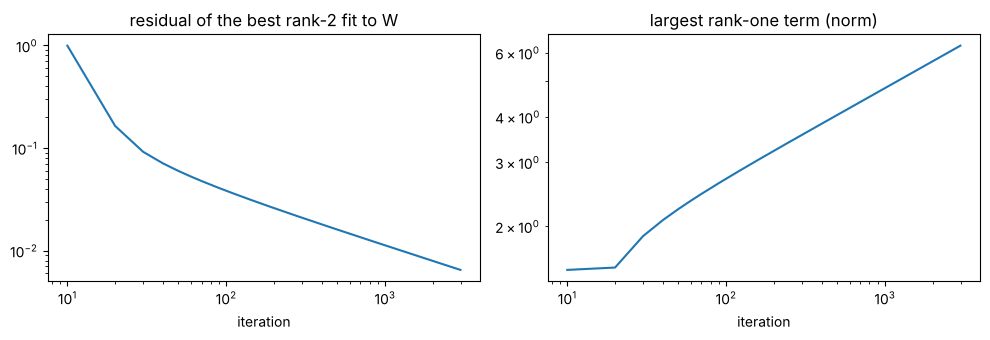

after 3000 iterations: residual 6.47e-03, largest rank-one term 6.3, while ||W|| = 1.732


In [5]:
Jrot = np.array([[0, -1], [1, 0]])
Trot = np.stack([np.eye(2), Jrot], axis=2)
for r in (2, 3):
    print(f"rotation tensor, real ALS with r = {r}:", " ".join(f"{als(Trot, r, 500, seed=s)[0]:.1e}" for s in range(5)))
t3 = lambda u, v, w: np.einsum("i,j,k->ijk", u, v, w)
D3 = t3([1, 1], [0, 1], [1, 0]) + t3([-1, 1], [1, 0], [0, 1]) + t3([1, 0], [1, -1], [1, 1])
print("explicit decomposition of the text is exact:", np.array_equal(D3, Trot))

E1, E2 = np.eye(2)
Wt = t3(E1, E1, E2) + t3(E1, E2, E1) + t3(E2, E1, E1)
res, _, hist = als(Wt, 2, iters=3000, ridge=0, seed=3, history=True)
hist = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(hist[1:, 0], hist[1:, 1]); ax[0].set_title("residual of the best rank-2 fit to W"); ax[0].set_xlabel("iteration")
ax[1].loglog(hist[1:, 0], hist[1:, 2]); ax[1].set_title("largest rank-one term (norm)"); ax[1].set_xlabel("iteration")
plt.tight_layout(); plt.show()
print(f"after 3000 iterations: residual {res:.2e}, largest rank-one term {hist[-1, 2]:.1f}, while ||W|| = {np.linalg.norm(Wt):.3f}")

Over $\R$ the rotation tensor refuses two terms and accepts three, as the slice test predicts. The W tensor is the textbook degenerate case: the residual creeps towards $0$ while the rank-one terms grow without bound and nearly cancel, the behaviour of the family $W_\varepsilon$. There is no best rank-$2$ approximation to converge to (Exercise 10.8).

### P10.5
**How to find it.** Reshape the state into its coefficient matrix and take singular values. A random state is a normalised complex Gaussian vector.

Bell state: Schmidt coefficients [0.7071 0.7071], entropy 1.0000
Exercise state: Schmidt coefficients [0.8539 0.5205], entropy 0.8428
random states in C^8 x C^8: mean entropy 2.2925 (Page's formula 2.2918), maximum possible 3


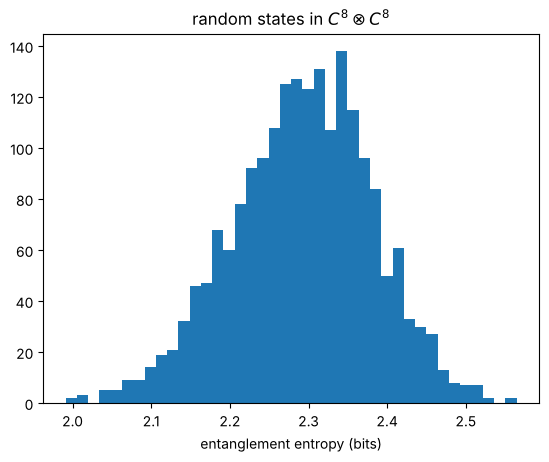

In [6]:
def schmidt(Psi):
    s = np.linalg.svd(Psi, compute_uv=False)
    p = s[s > 1e-12] ** 2
    return s, float(-(p * np.log2(p)).sum())

bell = np.eye(2) / math.sqrt(2)
print("Bell state: Schmidt coefficients %s, entropy %.4f" % (np.round(schmidt(bell)[0], 4), schmidt(bell)[1]))
psi = np.array([[1, 2], [2, 0]]) / 3
print("Exercise state: Schmidt coefficients %s, entropy %.4f" % (np.round(schmidt(psi)[0], 4), schmidt(psi)[1]))
ents = []
for _ in range(2000):
    Z = rng.standard_normal((8, 8)) + 1j * rng.standard_normal((8, 8))
    ents.append(schmidt(Z / np.linalg.norm(Z))[1])
page = sum(1 / k for k in range(9, 65)) / math.log(2) - 7 / (2 * 8 * math.log(2))
print(f"random states in C^8 x C^8: mean entropy {np.mean(ents):.4f} (Page's formula {page:.4f}), maximum possible 3")
plt.hist(ents, bins=40); plt.xlabel("entanglement entropy (bits)"); plt.title("random states in $C^8\\otimes C^8$"); plt.show()

Random states are almost maximally entangled: the mean entropy is about $2.28$ bits out of a possible $3$, in agreement with Page's formula $\sum_{k=n+1}^{mn}\frac1k-\frac{m-1}{2n}$ (in nats, for $m\le n$), conjectured by Don Page in 1993 and proved soon after. Entanglement is the rule, product states the exception.

### P10.6
**How to find it.** Build $A_m\otimes I+I\otimes A_n$ with `np.kron` and compare sorted eigenvalue lists.

grid eigenvalues match: True


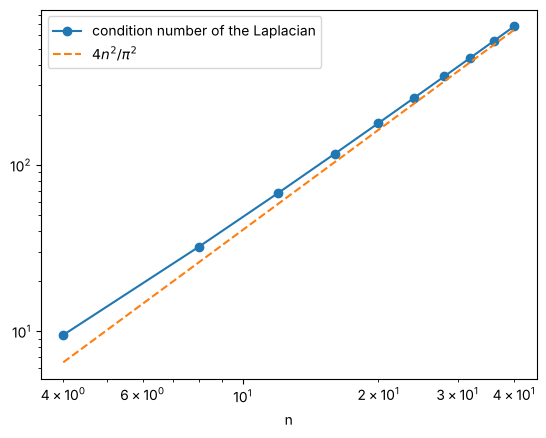

ratio at n = 40: 1.0496


In [7]:
def path(n):
    return np.diag(np.ones(n - 1), 1) + np.diag(np.ones(n - 1), -1)
m, n = 4, 6
G = np.kron(path(m), np.eye(n)) + np.kron(np.eye(m), path(n))
pred = sorted(2 * math.cos(math.pi * i / (m + 1)) + 2 * math.cos(math.pi * k / (n + 1)) for i in range(1, m + 1) for k in range(1, n + 1))
print("grid eigenvalues match:", np.allclose(np.sort(np.linalg.eigvalsh(G)), pred))
ns = np.arange(4, 41, 4); conds = []
for n in ns:
    Ln = 2 * np.eye(n) - path(n)
    L = np.kron(Ln, np.eye(n)) + np.kron(np.eye(n), Ln)
    conds.append(np.linalg.cond(L))
plt.loglog(ns, conds, "o-", label="condition number of the Laplacian")
plt.loglog(ns, 4 * ns**2 / np.pi**2, "--", label="$4n^2/\\pi^2$")
plt.xlabel("n"); plt.legend(); plt.show()
print("ratio at n = 40:", round(conds[-1] / (4 * 40**2 / math.pi**2), 4))

The condition number grows like $4n^2/\pi^2$, with ratio tending to $1$. Halving the mesh size quadruples the condition number, which is why iterative methods for such systems need the acceleration ideas of Chapter 12.